In [1]:
import pandas as pd
import numpy as np

df=pd.read_csv('Dataset 2.csv')
df.info()
print(df.isnull().sum().sum(), "missing |", df.duplicated().sum(), "duplicates")
#print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 32000 entries, 0 to 31999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   platform      32000 non-null  str    
 1   brand         32000 non-null  str    
 2   product_name  32000 non-null  str    
 3   category      32000 non-null  str    
 4   price         32000 non-null  int64  
 5   rating        32000 non-null  float64
 6   ram           32000 non-null  str    
 7   storage       32000 non-null  str    
 8   battery       32000 non-null  str    
 9   url           32000 non-null  str    
dtypes: float64(1), int64(1), str(8)
memory usage: 2.4 MB
0 missing | 0 duplicates


In [2]:
df = pd.read_csv('Dataset 2.csv')
df = df.drop(columns=["category", "url", "product_name"])

df["ram_gb"] = df["ram"].str.extract(r"(\d+)").astype(float)
df["battery_mah"] = df["battery"].str.extract(r"(\d+)").astype(float)
df["storage_gb"] = df["storage"].str.extract(r"(\d+)").astype(float)

df.loc[df["storage"].str.contains("TB"),"storage_gb"]*=1024
df = df.drop(columns=["ram", "storage", "battery"])
print(df.head())
print(df["storage_gb"].value_counts().to_dict())
df.describe().round(2)

           platform   brand  price  rating  ram_gb  battery_mah  storage_gb
0             Croma    Vivo  26216     4.6    16.0       5000.0       512.0
1  Reliance Digital   Apple  42356     4.0     4.0       4000.0       128.0
2            Myntra    Vivo  42332     3.8    12.0       4000.0       512.0
3             Croma  Xiaomi  72791     4.6     4.0       5500.0       512.0
4            Myntra    Vivo  74376     4.1    16.0       5500.0       512.0
{64.0: 6522, 256.0: 6433, 1024.0: 6387, 512.0: 6339, 128.0: 6319}


,price,rating,ram_gb,battery_mah,storage_gb
count,32000.00,32000.00,32000.00,32000.00,32000.00
mean,41786.40,4.22,9.16,5005.62,395.59
std,19291.79,0.40,4.30,706.71,349.25
min,8156.00,3.50,4.00,4000.00,64.00
25%,25133.75,3.90,6.00,4500.00,128.00
50%,39922.00,4.20,8.00,5000.00,256.00
75%,57761.00,4.50,12.00,5500.00,512.00
max,81894.00,5.00,16.00,6000.00,1024.00


Text(0.5, 1.0, 'Price distribution')

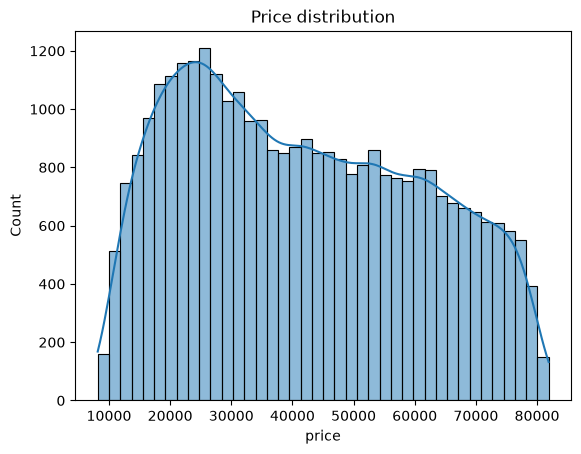

In [3]:
import matplotlib.pyplot as plt, seaborn as sns
sns.histplot(df.price, bins=40, kde=True).set_title("Price distribution")

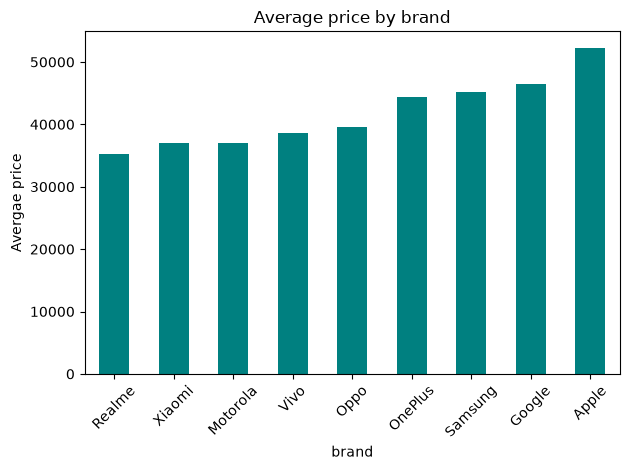

In [4]:
import matplotlib.pyplot as plt
df.groupby("brand")["price"].mean().sort_values().plot(kind="bar", color="teal")
plt.title("Average price by brand")
plt.ylabel("Avergae price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

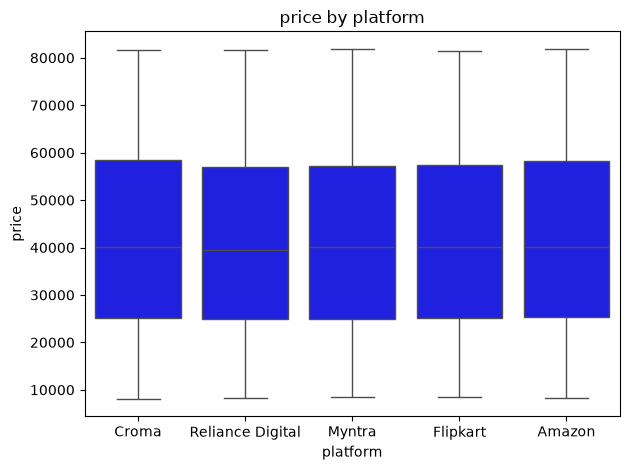

In [5]:
sns.boxplot(data=df,x="platform",y="price",color="blue")
plt.title("price by platform")
plt.xlabel("platform")
plt.ylabel("price")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split, GridSearchCV
num_cols=["battery_mah","rating","ram_gb","storage_gb"]
cat_cols=["brand","platform"]
X, y = df[num_cols + cat_cols], df["price"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape,X_test.shape)

(25600, 6) (6400, 6)


In [7]:
Q1=y_train.quantile(0.25)
Q3=y_train.quantile(0.75)

IQR=Q3-Q1

low=Q1-1.5*IQR
high=Q3+1.5*IQR

below=(y_train<low).sum()
above=(y_train>high).sum()

print("Lower limit:", low)
print("Upper limit:", high)
print("Outliers below:", below)
print("Outliers above:", above)

y_train_cap=y_train.clip(lower=low,upper=high)


Lower limit: -23902.0
Upper limit: 106710.0
Outliers below: 0
Outliers above: 0


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge

num_transform=StandardScaler()
cat_transform=OneHotEncoder(handle_unknown="ignore")

pre=ColumnTransformer([
    ("num",num_transform,num_cols,),
    ("cat",cat_transform,cat_cols)
])

lr=Pipeline([
    ("preprocessing",pre),
    ("model",LinearRegression())
])

lr.fit(X_train,y_train_cap)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['battery_mah','rating','ram_gb','storage_gb','brand','platform']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis conc

{'model': 'Linear Regression', 'rsme': 18339.095, 'mse': 15245.054, 'r2': 0.089, 'r2_train': 0.084}


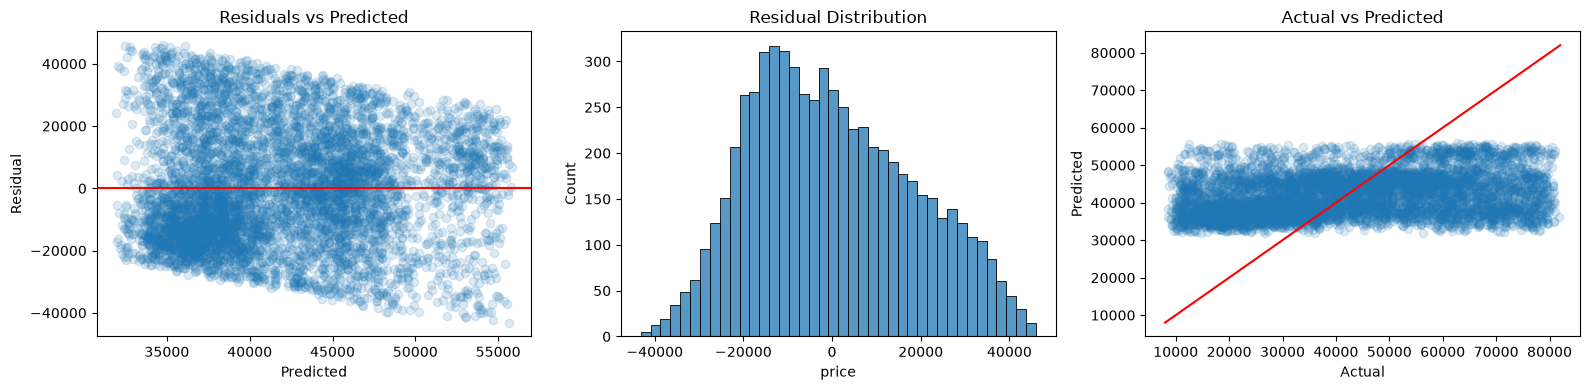

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results=[]

def evaluate(model,name):
    p=model.predict(X_test)

    r={
        "model":name,
        "rsme":float(np.sqrt(mean_squared_error(y_test,p))),
        "mse":float(mean_absolute_error(y_test,p)),
        "r2":float(r2_score(y_test,p)),
        "r2_train":float(r2_score(y_train,model.predict(X_train)))
    }

    results.append(r)

    print({
        k: round(v, 3) if isinstance(v, float) else v
        for k, v in r.items()
    })

    return p

pred=evaluate(lr,"Linear Regression")

res=y_test-pred

fig,ax=plt.subplots(1,3,figsize=(16,4))

# Graph 1: Residuals vs Predicted values
ax[0].scatter(pred,res,alpha=0.15)
ax[0].axhline(0,color="red")
ax[0].set(
    title="Residuals vs Predicted",
    xlabel="Predicted",
    ylabel="Residual"
)


#Graph 2: Distribution of residuals
sns.histplot(res,bins=40,ax=ax[1])
ax[1].set_title("Residual Distribution")

#Graph 3:  Actual vs Predicted values
ax[2].scatter(y_test,pred, alpha=0.15)
ax[2].plot([8000, 82000], [8000, 82000], "r")
ax[2].set(
    title="Actual vs Predicted",
    xlabel="Actual",
    ylabel="Predicted"
)

plt.tight_layout()
FIG = "figures/"
plt.savefig(FIG + "residuals.png", dpi=110)
plt.show()


In [10]:
import json, os


ridge = Pipeline([
    ("preprocessing", pre),
    ("model", Ridge())
])

grid = GridSearchCV(
    ridge,
    param_grid={
        "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
    },
    cv=5,
    scoring="r2"
)

grid.fit(X_train, y_train_cap)

print("Best alpha:", grid.best_params_["model__alpha"])

best = grid.best_estimator_

Best alpha: 10


{'model': 'Ridge (tuned)', 'rsme': 18339.437, 'mse': 15247.597, 'r2': 0.089, 'r2_train': 0.084}


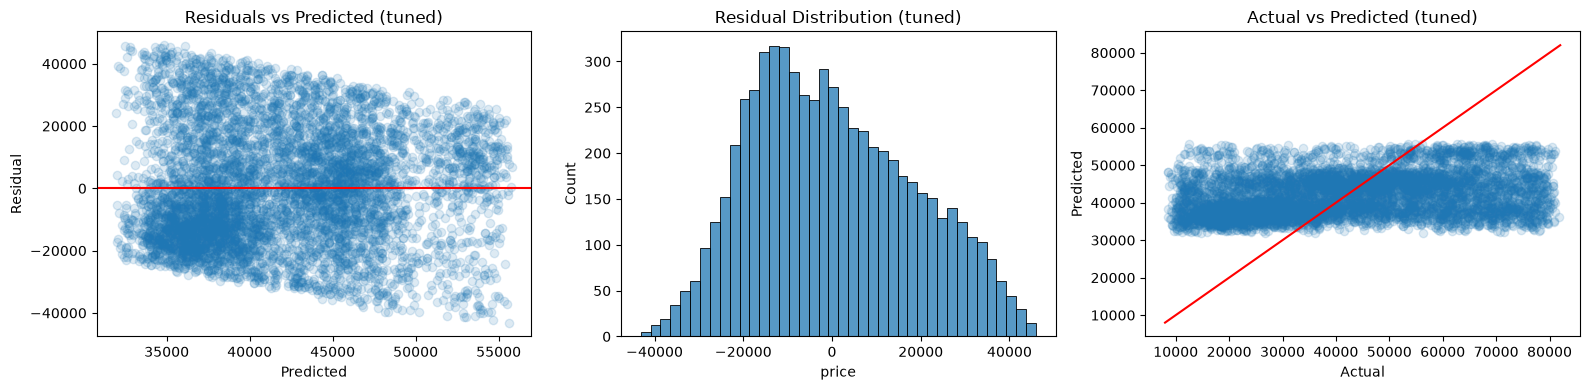

In [14]:

pred_best = evaluate(best, "Ridge (tuned)")
#print(pd.DataFrame(results).round(3))

res_best = y_test - pred_best
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(pred_best, res_best, alpha=0.15)
ax[0].axhline(0, color="red")
ax[0].set(title="Residuals vs Predicted (tuned)", xlabel="Predicted", ylabel="Residual")
sns.histplot(res_best, bins=40, ax=ax[1])
ax[1].set_title("Residual Distribution (tuned)")
ax[2].scatter(y_test, pred_best, alpha=0.15)
ax[2].plot([8000, 82000], [8000, 82000], "r")
ax[2].set(title="Actual vs Predicted (tuned)", xlabel="Actual", ylabel="Predicted")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/residuals_tuned.png", dpi=110)
plt.show()








In [ ]:
pre_fit = best.named_steps["preprocessing"]
scaler = pre_fit.named_transformers_["num"]
brands = [str(b) for b in pre_fit.named_transformers_["cat"].categories_[0]]
platforms = [str(p) for p in pre_fit.named_transformers_["cat"].categories_[1]]
coef = best.named_steps["model"].coef_
n = len(num_cols)

names = num_cols + ["brand_" + b for b in brands] + ["platform_" + p for p in platforms]
importance = pd.Series(coef, index=names).abs().sort_values()
importance.tail(10).plot(kind="barh", color="teal")
plt.title("Top 10 features (size of coefficient)")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=110)
plt.show()

+1 unit of battery_mah: Rs 0
+1 unit of rating: Rs 4,642
+1 unit of ram_gb: Rs -12
+1 unit of storage_gb: Rs -0


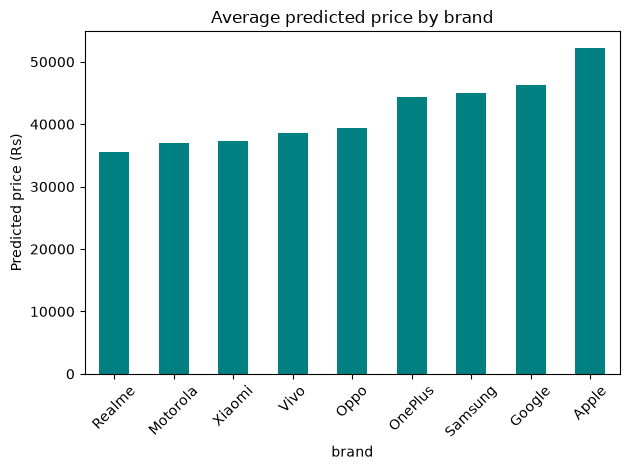

In [12]:
# ---------- Price sensitivity: how much each unit adds (in Rs) ----------
per_unit = coef[:n] / scaler.scale_
for c, v in zip(num_cols, per_unit):
    print(f"+1 unit of {c}: Rs {v:,.0f}")

# ---------- Brand premium: average predicted price by brand ----------
premium = (pd.Series(pred_best, index=X_test.index)
           .groupby(X_test["brand"]).mean().sort_values())
premium.plot(kind="bar", color="teal")
plt.title("Average predicted price by brand")
plt.ylabel("Predicted price (Rs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/brand_premium.png", dpi=110)
plt.show()

In [13]:

last = results[-1]
model_js = {
    "intercept": float(best.named_steps["model"].intercept_),
    "num": {
        c: {"mean": float(m), "scale": float(s), "coef": float(w)}
        for c, m, s, w in zip(num_cols, scaler.mean_, scaler.scale_, coef[:n])
    },
    "brand": dict(zip(brands, map(float, coef[n:n + len(brands)]))),
    "platform": dict(zip(platforms, map(float, coef[n + len(brands):]))),
    "lower": float(low),
    "upper": float(high),
    "options": {
        "ram_gb": sorted(float(v) for v in df["ram_gb"].unique()),
        "storage_gb": sorted(float(v) for v in df["storage_gb"].unique()),
        "battery_mah": {"min": float(df["battery_mah"].min()),
                        "max": float(df["battery_mah"].max()),
                        "default": float(df["battery_mah"].median())},
        "rating": {"min": float(df["rating"].min()), "max": float(df["rating"].max())},
    },
    "brand_premium": {str(k): float(v) for k, v in premium.items()},
    "metrics": {"rmse": last["rsme"], "mae": last["mse"], "r2": last["r2"]},
}

os.makedirs("web", exist_ok=True)
with open("web/model.js", "w") as f:
    f.write("const MODEL = " + json.dumps(model_js, indent=2) + ";")
print("Saved web/model.js")


Saved web/model.js
